# CsI(Tl)–SiPM：冻结参数下的独立Geant4统计复现

2026-10-30，承接[原始波形与尾部诊断](codex_0001_csi_waveform_tail.ipynb)。上一轮的基线/定位对照没有可靠解决外侧分位宽度差异，受支持Am模拟仅180个母事件。
本轮在新数值结果出现前冻结参数、种子、母事件数、筛选、目标权重、评价指标和小样本检查，随后进行新的完整核衰变、光学输运、SiPM雪崩和原生ADC模拟。
**4批独立种子，每批16,000个Co及48,000个Am，共256,000个新母衰变；原模型和两种固定响应共用同批物理历史。**
模拟统计复现不增加实验数据。实验各段此前均已探索，响应按采集段条件化；本轮不拟合、不选优、不替换默认配置或正式PID。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/mc_statistics_20261030'
def read(path):return json.loads(Path(path).read_text())
def fmt(x,n=3):return '不可估计' if x is None else f'{x:.{n}f}'
def nums(x):return ' / '.join(fmt(v) for v in x)
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+']'
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');e=read(OUT/'analysis.json');decision=read(OUT/'decision.json')
variants=p['variants'];labels={'frozen':'原冻结','inherited_CV_fit':'连续RC+原谱/CV','spectrum_CV_fit':'连续RC+扩展谱/CV'}
methods=['QDC','negative_mean_time','PCA']
print('方案冻结时提交:',p['checkpoint_commit'])
print('新完整母事件:',e['new_independent_mothers'],'下游重放记录:',e['replay_entries'])
display(Markdown(decision['conclusion_zh']))

方案冻结时提交: b80bdb374724d7c01379a77497d4b44b80223a2b
新完整母事件: 256000 下游重放记录: 91525


完成256000个独立Geant4母衰变，固定Q支持内获得Co 2175、Am 1406个新母事件。冻结扩展谱在Am晚段（块128）的平均时间95%宽度比，从旧样本0.872变为新合并样本0.980，条件95%区间[0.914,1.120]；新减旧的配对区间为[-0.065,0.265]。两源核心及95%宽度的12项检查中，2项条件区间不含1。这些区间未包含拟合和模型不确定性，也未作多重比较校正或等效性检验；本轮不宣称全面一致，默认配置和正式PID保持原样。

## 1. 独立性、源与装置边界

完整输运使用原联合候选的同一Geant4可执行文件和逐字节相同的配置；新种子不同于原校准/检查种子。
保留10×10×10 mm³ CsI(Tl)、PTFE包裹、5 μm Mylar及原阵列求和假设。源距等尚未独立标定的参数继续作为冻结假设，不能因波形相近称其已被唯一确定。
母事件包括零沉积及不进入共同Q区间的事件，完整保存于ROOT；不是把已有波形重放256,000次。
²⁴¹Am衰变中的α、γ和电子均由原物理模型处理，不将实验Am主带当作纯α真值。

两种候选响应沿用前轮各段/块长/评价折选中的RC、电压传输、前触发噪声谱和信号相关残差参数。
新雪崩历史由C++读出模块重放；每条新入选母事件还需通过原配置、零相位的ADC逐点一致检查。
同一母事件的多个响应不计为新增独立事件；原母事件不与新母事件合并估计本轮点值。


|批|源|完整输运种子|原母事件数|共同Q入选数|六个Q箱原数|能量90%家族α/γ/电子/混合/无沉积数|物理/数值检查|
|---|---|---|---|---|---|---|---|
|1|Am241|731030012|48000|372|[118, 155, 77, 21, 1, 0]|[372, 0, 0, 0, 0]|True|
|1|Co60|731030003|16000|573|[90, 104, 97, 106, 80, 96]|[0, 572, 1, 0, 0]|True|
|2|Am241|731031012|48000|376|[113, 159, 87, 16, 1, 0]|[376, 0, 0, 0, 0]|True|
|2|Co60|731031003|16000|523|[98, 89, 77, 75, 97, 87]|[0, 521, 2, 0, 0]|True|
|3|Am241|731032012|48000|366|[109, 158, 78, 20, 1, 0]|[366, 0, 0, 0, 0]|True|
|3|Co60|731032003|16000|552|[90, 99, 96, 80, 96, 91]|[0, 551, 1, 0, 0]|True|
|4|Am241|731033012|48000|372|[122, 146, 84, 17, 3, 0]|[372, 0, 0, 0, 0]|True|
|4|Co60|731033003|16000|527|[84, 83, 92, 76, 91, 101]|[0, 526, 1, 0, 0]|True|

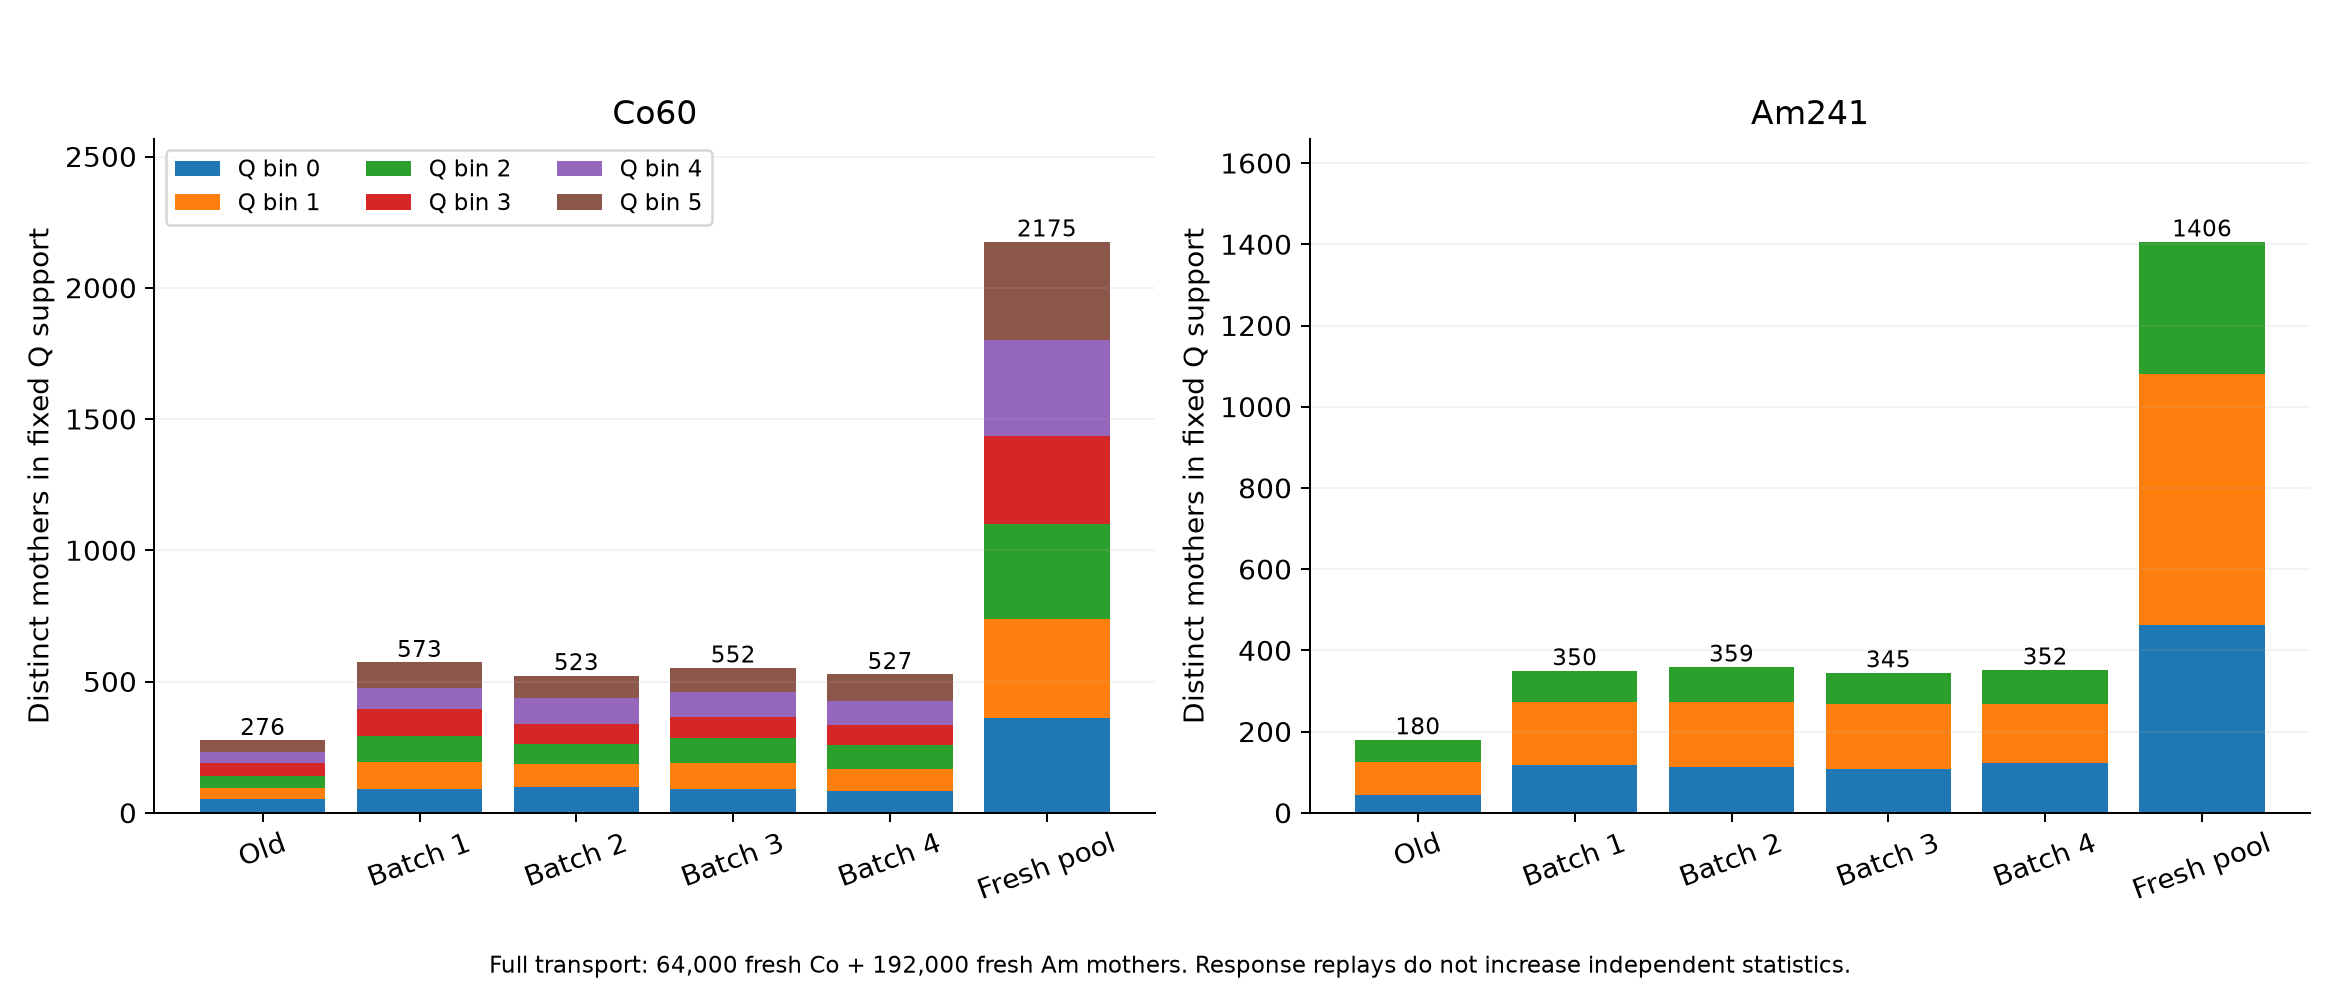

In [2]:
rows=[]
for key,entry in sorted(p['entries'].items()):
    x=read(OUT/'transport/extraction'/f'{key}.json')
    v=read(OUT/'native'/f'{key}_validation.json')
    rows.append([entry['batch']+1,entry['source'],entry['seed'],entry['events'],x['n_common'],x['common_Q_bins'],x['common_truth_counts'],v['passed']])
display(Markdown(table(['批','源','完整输运种子','原母事件数','共同Q入选数','六个Q箱原数','能量90%家族α/γ/电子/混合/无沉积数','物理/数值检查'],rows)))
display(Image(filename=str(OUT/'figures/independent_MC_support.png')))

## 2. 固定筛选、权重和响应分配

只从每批原配置ADC应用既有质量检查、峰幅≥200 ADC、t₁₀≥384样点及原共同Q区间，保留该批全事件基线RMS中位数作为原质量算法的参考。
一旦入选，各响应固定相同原ID和原Q；不按候选响应重新选择，不删除诊断尾部，也不按粒子真值选择。
Co支持6个Q箱，Am支持前3箱；Q箱内两半的目标质量仍来自原实验first60，箱间等权。新Q、原Q和样本量区分保存。

原实验按`(原ID // 块长) % 2`分折，块128为主、64为敏感性检查。
新母事件按预定随机流分配到两个已冻结响应，分配概率等于该实验组原Q权重下的折质量；一条母事件在同一条件内仅取一份响应。
分配不使用新波形得分或拟合结果。另列每Q箱的事件数、两半数、有效样本量及折份额，检查匹配支持。


In [3]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128']['variants']['spectrum_CV_fit']['support']
    for b,r in g['Q_bins'].items():
        rows.append([run,b,r['count'],r['Q_half_counts'],fmt(r['ESS'],1),r['fold_counts'],fmt(r['fold0_weight'])])
display(Markdown(table(['run晚段','Q箱','新母事件数','原Q两半数','ESS','两折数','折0权重'],rows)))
print('两源原Q区间:',p['q_edges'])

两源原Q区间: [201824.1125, 237975.62708333333, 274127.14166666666, 310278.65625, 346430.17083333334, 382581.6854166667, 418733.2]


|run晚段|Q箱|新母事件数|原Q两半数|ESS|两折数|折0权重|
|---|---|---|---|---|---|---|
|3|0|362|[229, 133]|334.2|[173, 189]|0.480|
|3|1|375|[221, 154]|362.1|[203, 172]|0.535|
|3|2|362|[209, 153]|353.3|[164, 198]|0.454|
|3|3|337|[207, 130]|319.1|[169, 168]|0.507|
|3|4|364|[188, 176]|363.6|[188, 176]|0.516|
|3|5|375|[128, 247]|337.2|[190, 185]|0.511|
|12|0|462|[184, 278]|443.2|[240, 222]|0.513|
|12|1|618|[258, 360]|601.7|[299, 319]|0.479|
|12|2|326|[195, 131]|313.4|[162, 164]|0.497|

## 3. 核心与外侧宽度：旧样本与新合并样本

保留原50/80/90/95%中心分位跨度，箱内跨度平方等权平均后开根号；SD来自未裁剪的完整箱内协方差。
同时检查三个得分中心、完整协方差误差、绝对均ADC、F50/102/202均值及事件间SD、冻结诊断尾部质量及方差贡献、固定三维形状模式，共51项指标。

512次实验原索引块与模拟完整母事件重采样。新模拟在每个种子批内重采样，以保留四个预定批次规模；入选类别加“全部未入选”类别的多项分布与完整母事件bootstrap的所需边缘分布等价。
各模型共用相同母事件计数。旧母事件独立重采样，旧/新比较共用同一次实验块抽样；旧区间在本轮随机流下重算，点定义与旧记录一致。
参数、模式、尾部边界、分配、Q目标/PCA固定，未包含其拟合或选择的不确定性。旧MC曾参与校准，因此旧/新之差不是纯粹、可唯一归因的统计噪声估计。


|晚段run|固定响应|旧QDC/−t/PCA核心比|新核心比|旧95%宽度比|新95%宽度比|
|---|---|---|---|---|---|
|3|原冻结|0.997 / 0.940 / 1.015|1.020 / 0.941 / 0.929|0.992 / 0.973 / 0.975|1.045 / 0.979 / 1.013|
|3|连续RC+原谱/CV|0.987 / 0.933 / 1.015|1.015 / 0.935 / 0.918|0.981 / 0.968 / 0.966|1.047 / 0.977 / 1.006|
|3|连续RC+扩展谱/CV|1.060 / 0.956 / 1.037|1.066 / 0.957 / 0.951|1.002 / 1.004 / 0.975|1.072 / 1.006 / 1.038|
|12|原冻结|1.058 / 0.917 / 1.096|0.946 / 0.839 / 0.925|0.928 / 0.776 / 0.900|1.023 / 0.866 / 0.938|
|12|连续RC+原谱/CV|1.120 / 0.942 / 1.087|0.984 / 0.881 / 0.949|0.971 / 0.822 / 0.965|1.051 / 0.914 / 0.995|
|12|连续RC+扩展谱/CV|1.160 / 0.981 / 1.148|1.014 / 0.941 / 1.005|1.024 / 0.872 / 1.024|1.090 / 0.980 / 1.034|

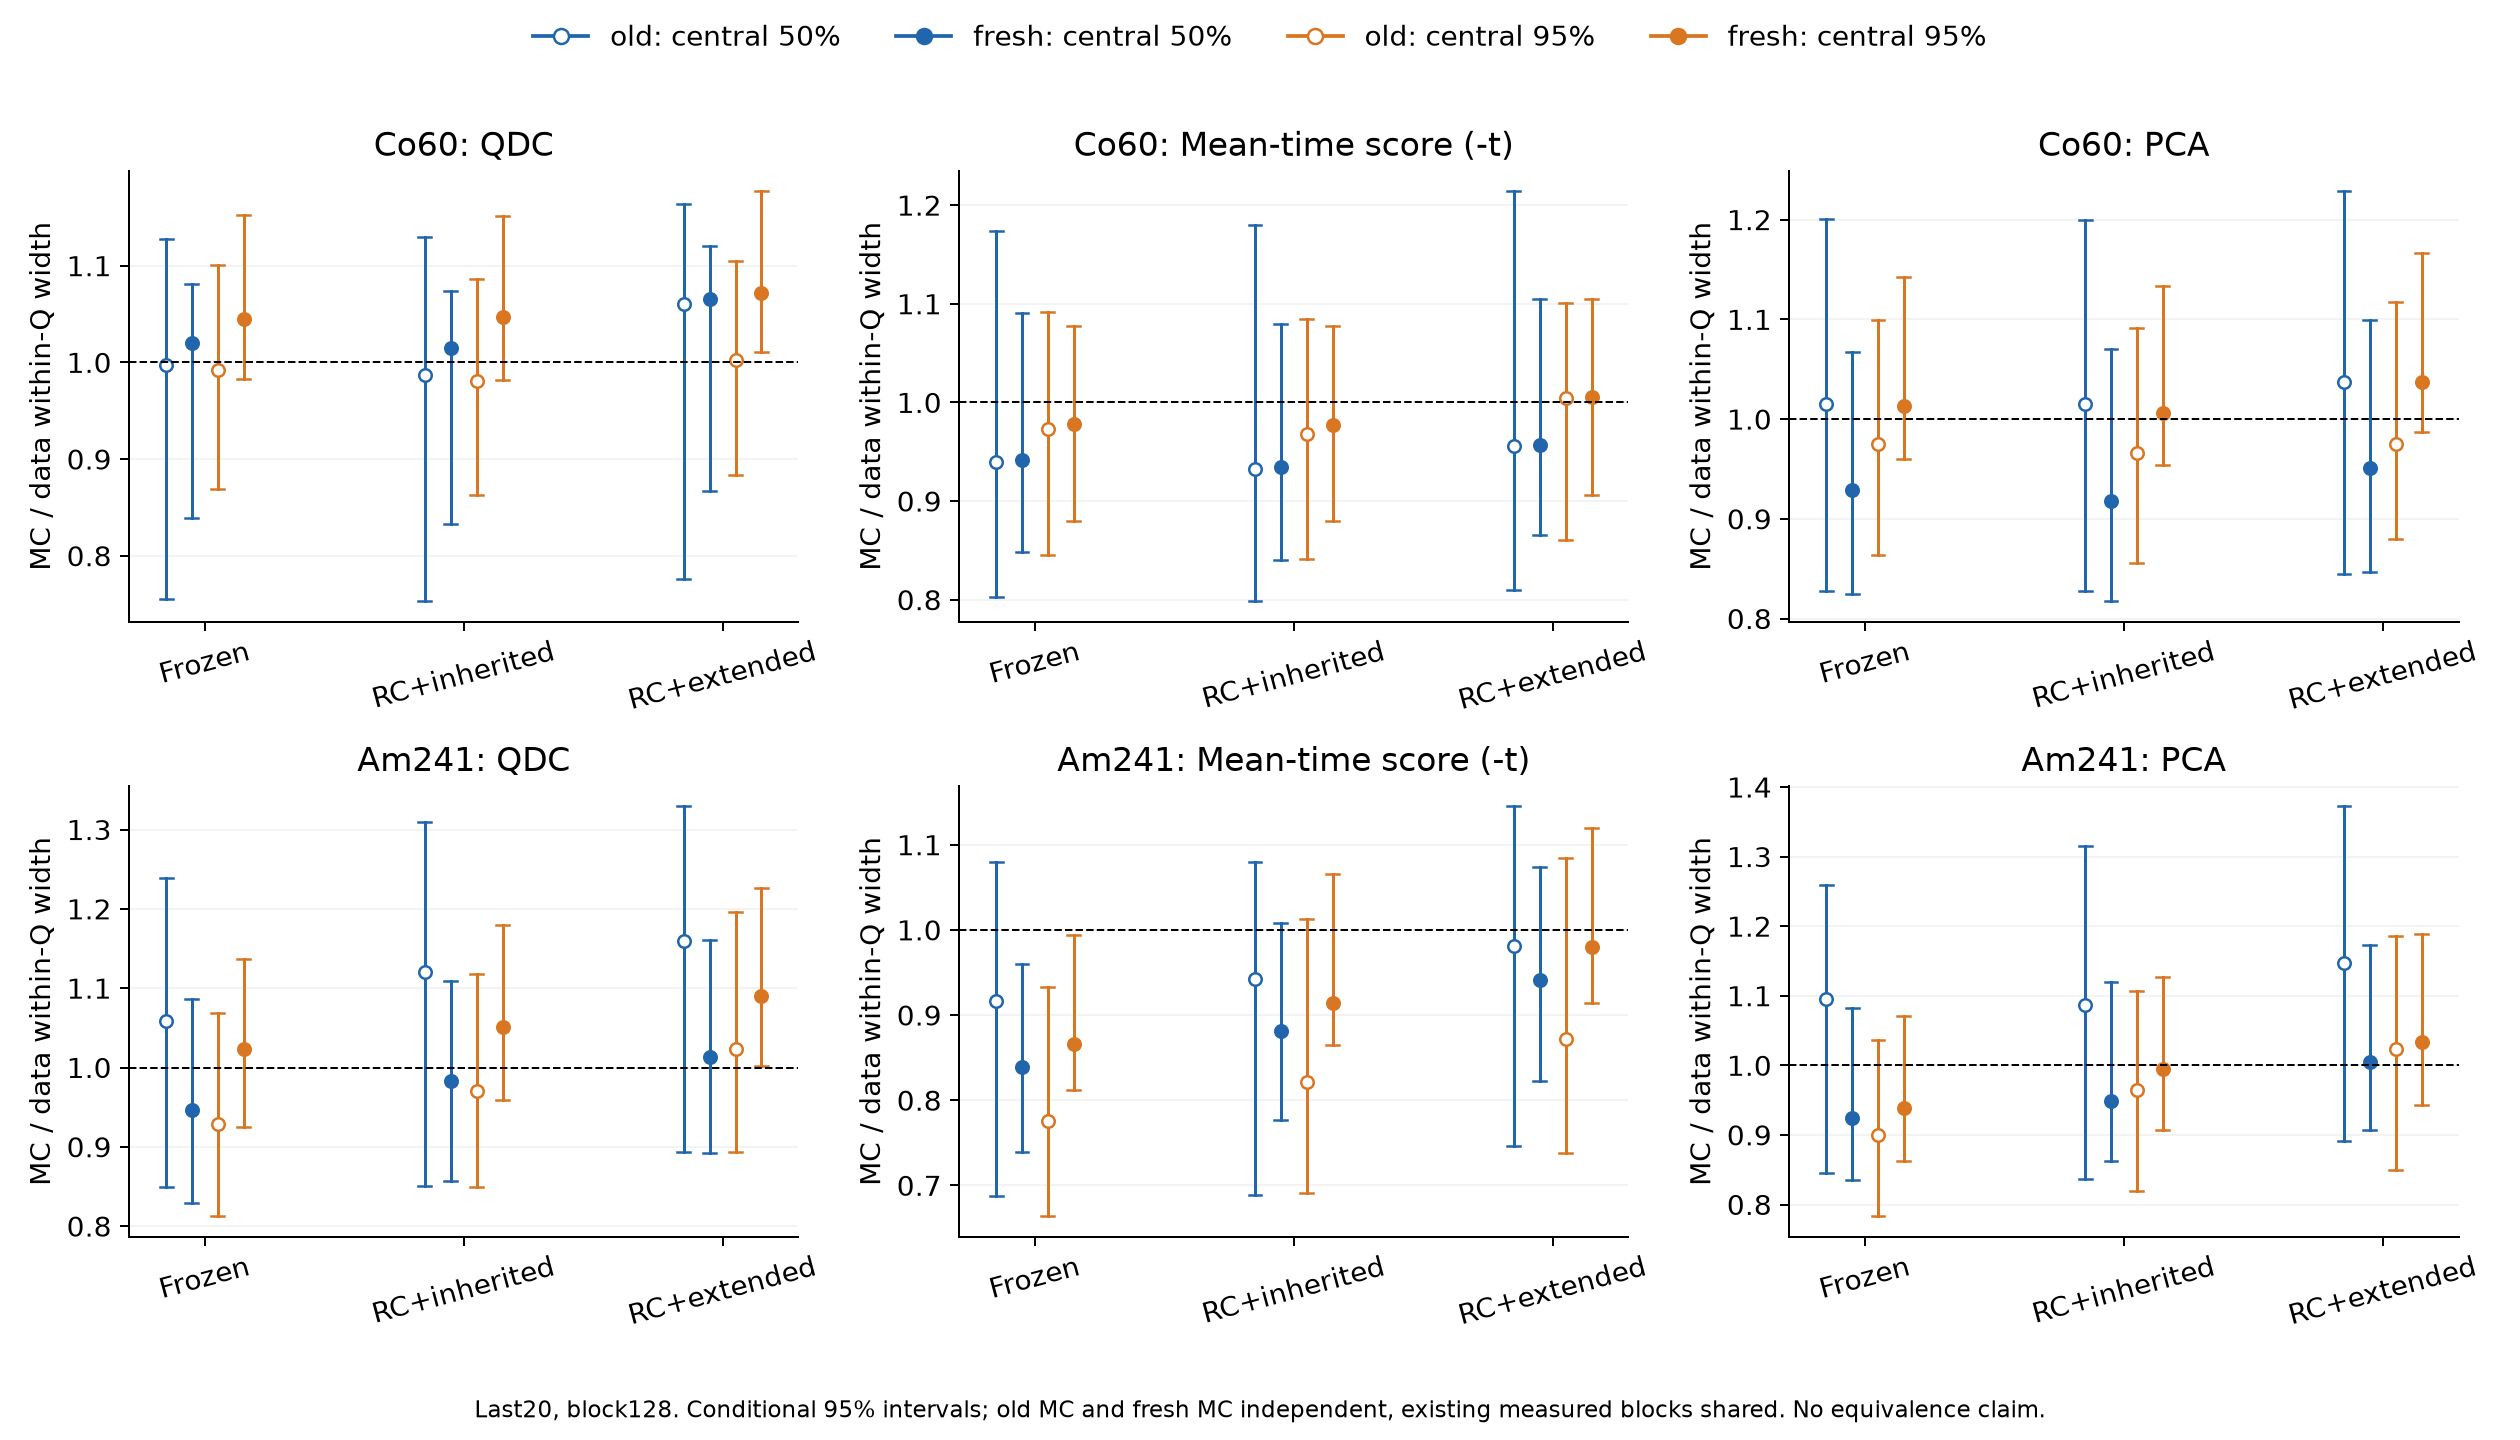

In [4]:
rows=[]
for run in [3,12]:
    for v in variants:
        r=e['groups'][f'run{run}_last20']['128']['variants'][v]
        rows.append([run,labels[v],nums([r['old_point'][f'width50_{m}_ratio'] for m in methods]),nums([r['point'][f'width50_{m}_ratio'] for m in methods]),nums([r['old_point'][f'width95_{m}_ratio'] for m in methods]),nums([r['point'][f'width95_{m}_ratio'] for m in methods])])
display(Markdown(table(['晚段run','固定响应','旧QDC/−t/PCA核心比','新核心比','旧95%宽度比','新95%宽度比'],rows)))
display(Image(filename=str(OUT/'figures/independent_PID_quantiles.png')))

|组|块长|旧平均时间95%比|新比|新条件95%区间|新减旧配对区间|
|---|---|---|---|---|---|
|run3_first60|64|0.945|0.941|[0.871, 1.008]|[-0.077, 0.116]|
|run3_first60|128|0.953|0.943|[0.872, 1.010]|[-0.079, 0.110]|
|run3_middle20|64|0.957|0.975|[0.880, 1.089]|[-0.069, 0.122]|
|run3_middle20|128|0.945|0.957|[0.876, 1.080]|[-0.066, 0.129]|
|run3_last20|64|1.029|1.030|[0.909, 1.139]|[-0.097, 0.134]|
|run3_last20|128|1.004|1.006|[0.907, 1.105]|[-0.067, 0.122]|
|run12_first60|64|0.887|1.021|[0.938, 1.094]|[-0.027, 0.260]|
|run12_first60|128|0.896|1.007|[0.940, 1.085]|[-0.020, 0.246]|
|run12_middle20|64|0.905|1.017|[0.899, 1.160]|[-0.033, 0.273]|
|run12_middle20|128|0.898|1.005|[0.905, 1.162]|[-0.014, 0.278]|
|run12_last20|64|0.840|0.995|[0.920, 1.159]|[-0.001, 0.294]|
|run12_last20|128|0.872|0.980|[0.914, 1.120]|[-0.065, 0.265]|

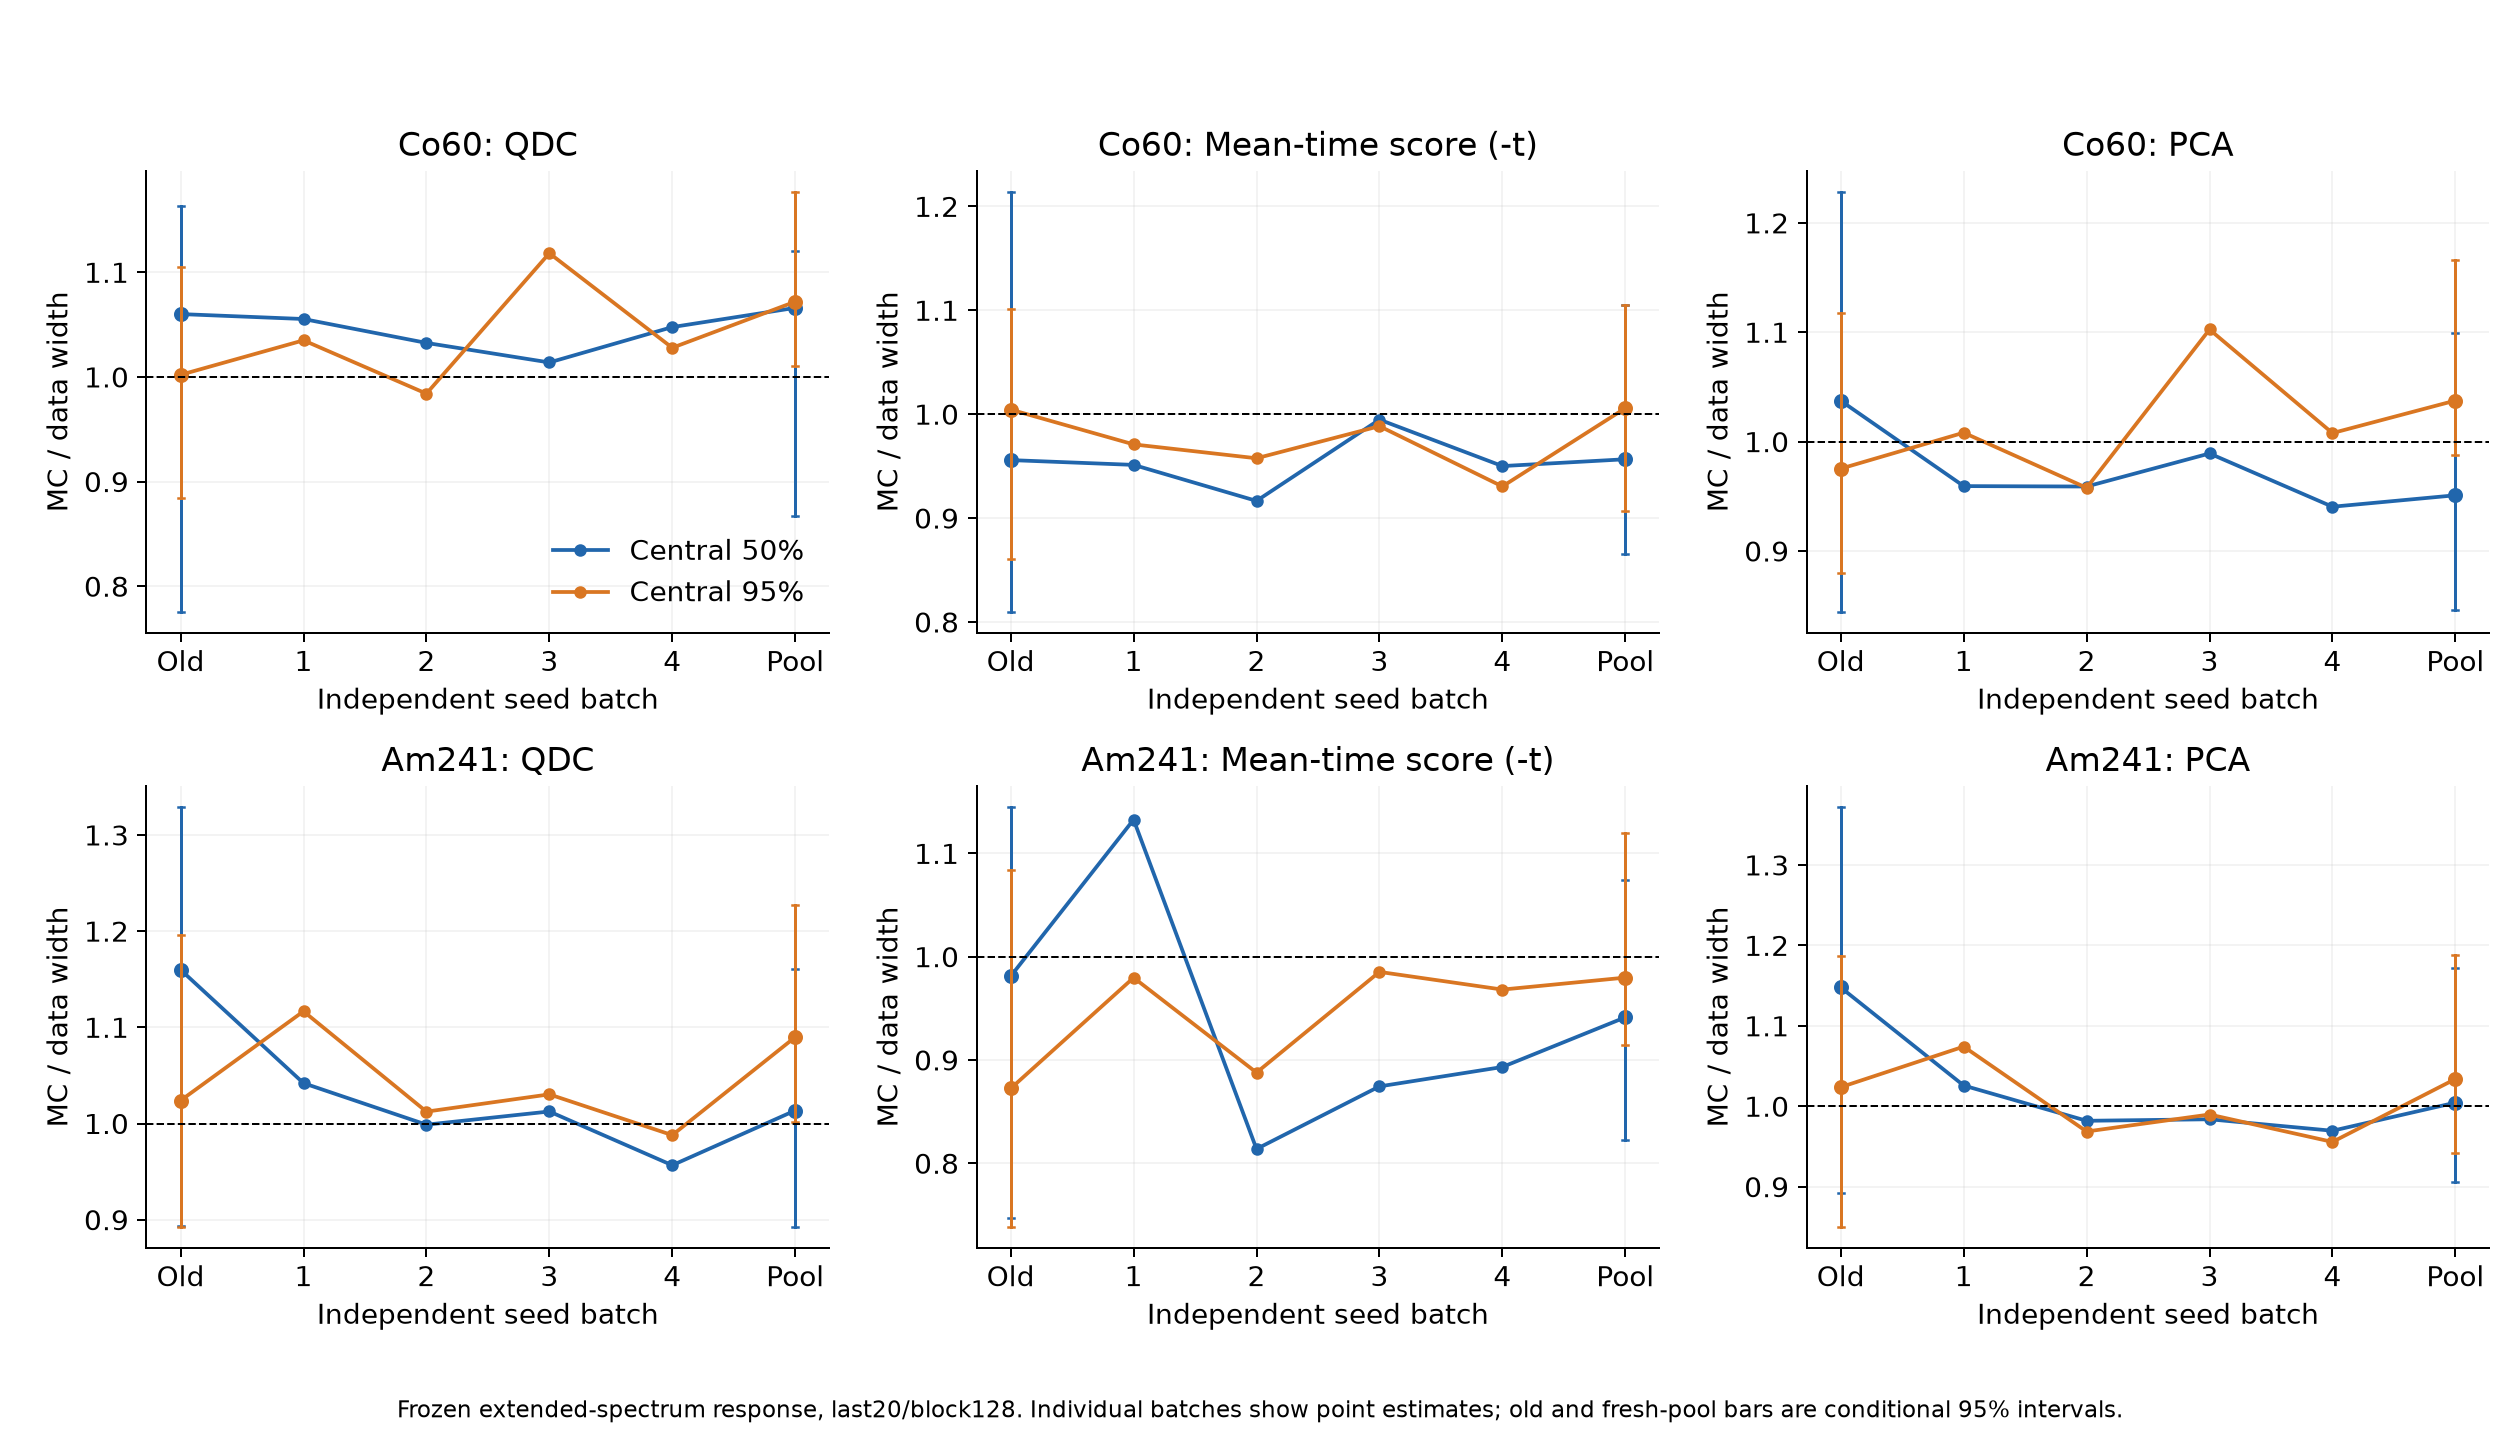

In [5]:
rows=[]
name='width95_negative_mean_time_ratio'
for key,blocks in e['groups'].items():
    for B,g in blocks.items():
        r=g['variants']['spectrum_CV_fit']
        rows.append([key,B,fmt(r['old_point'][name]),fmt(r['point'][name]),ci(r['CI95'][name]),ci(r['fresh_minus_old_CI95'][name])])
display(Markdown(table(['组','块长','旧平均时间95%比','新比','新条件95%区间','新减旧配对区间'],rows)))
display(Image(filename=str(OUT/'figures/independent_batch_stability.png')))

## 4. 平均ADC、起伏和形状方差

平均波形来自原生ADC减各事件原基线，再按相同Q目标汇总；每条波形没有按实测事件重新缩放。
图中按40 ns汇总显示，与均波形评价使用的76个门内分箱相同；PID积分仍使用2 ns原ADC。
`mean_ADC_NRMSE`沿用前轮定义，实际为平均波形残差的L2范数除实测均波形L2范数；图中残差则以实测峰值表示百分比，两者分母不同。

固定三维子空间及每Q箱基准形状来自上一轮对折实验训练，没有在新MC重训。
每个评价Q箱/折按该组自己的均值居中，三模式内与正交剩余方差严格相加为全形状方差；对训练基准的均值偏离另存。
这些是统计方向，不直接等于三个物理噪声机制。F、PID和形状份额共享样点/归一化，相关性不能单独识别原因。


|run|固定响应|时间中心MC−实测/ns|条件95%区间|均ADC相对L2误差/%|归一协方差误差|F50/102/202均值比|
|---|---|---|---|---|---|---|
|3|原冻结|-1.176|[-2.588, 0.299]|3.231|0.073|1.030 / 1.038 / 1.018|
|3|连续RC+原谱/CV|0.740|[-0.672, 2.232]|2.998|0.080|1.013 / 1.020 / 0.997|
|3|连续RC+扩展谱/CV|0.770|[-0.657, 2.262]|2.997|0.038|1.006 / 1.016 / 1.000|
|12|原冻结|7.206|[2.198, 12.103]|1.871|0.161|1.050 / 1.026 / 1.033|
|12|连续RC+原谱/CV|0.628|[-4.416, 5.554]|1.582|0.087|1.021 / 1.002 / 1.019|
|12|连续RC+扩展谱/CV|0.671|[-4.439, 5.760]|1.597|0.055|1.005 / 0.989 / 1.010|

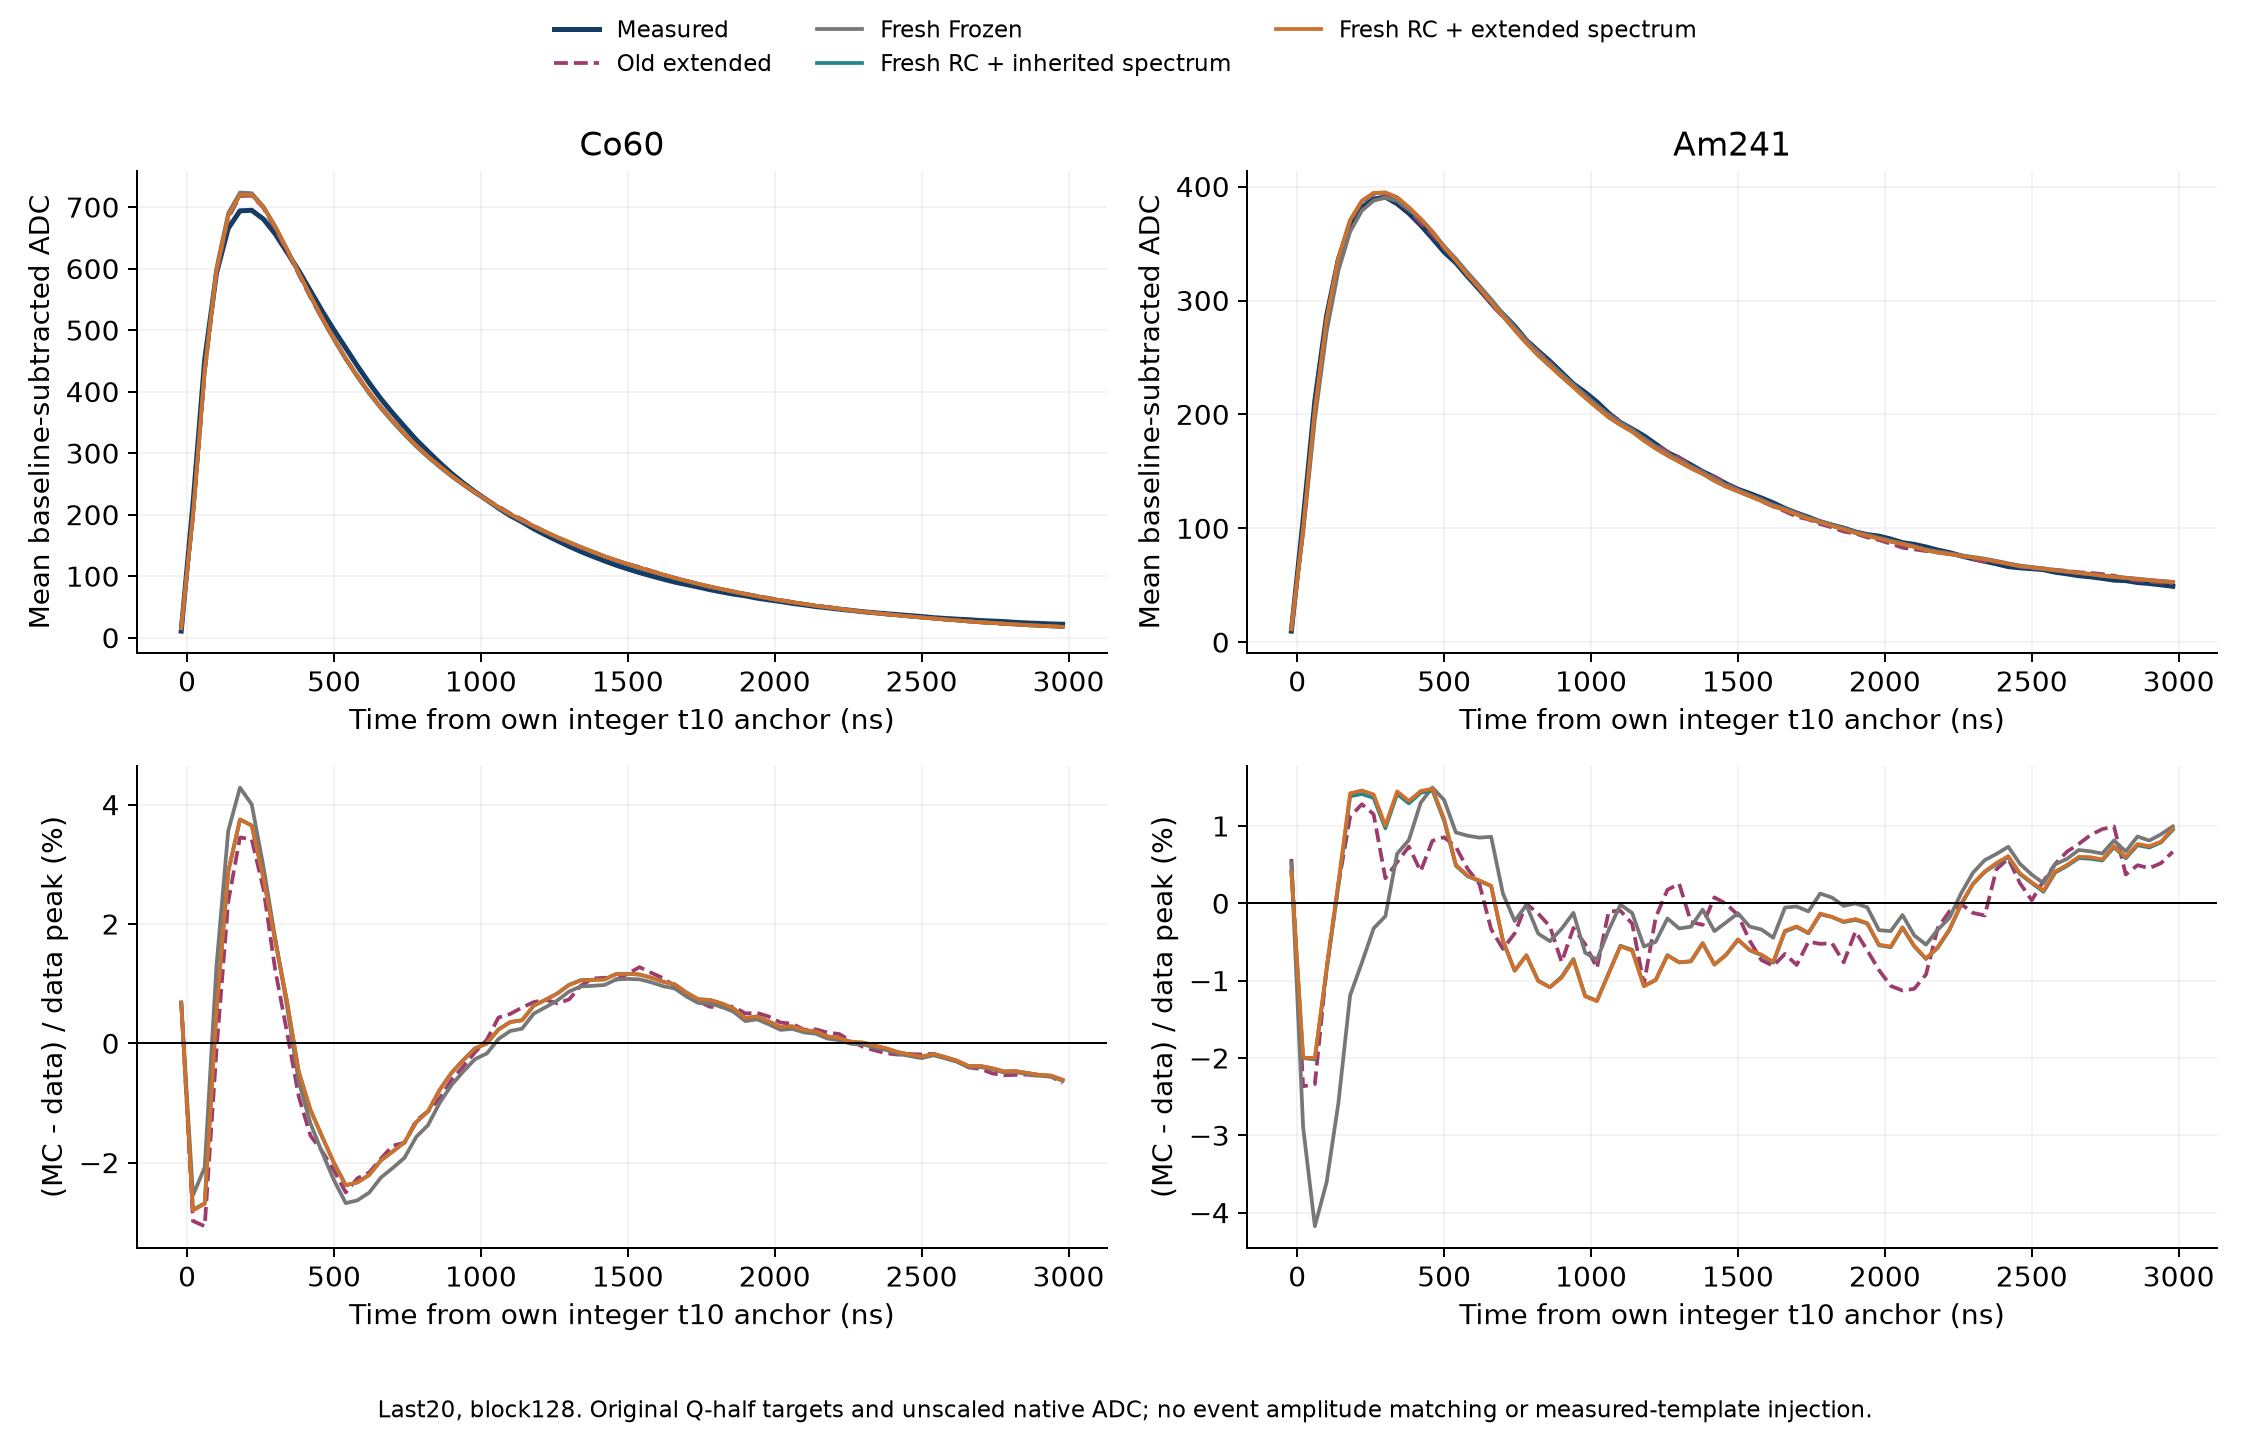

In [6]:
rows=[]
for run in [3,12]:
    for v in variants:
        r=e['groups'][f'run{run}_last20']['128']['variants'][v];a=r['point']
        rows.append([run,labels[v],fmt(a['mean_time_delta_ns']),ci(r['CI95']['mean_time_delta_ns']),fmt(100*a['mean_ADC_NRMSE']),fmt(a['covariance_normalized_RMSE']),nums([a[f'F{w}_ratio'] for w in [50,102,202]])])
display(Markdown(table(['run','固定响应','时间中心MC−实测/ns','条件95%区间','均ADC相对L2误差/%','归一协方差误差','F50/102/202均值比'],rows)))
display(Image(filename=str(OUT/'figures/independent_native_mean_ADC.png')))

|run晚段|指标|旧比|新比|新条件95%区间|
|---|---|---|---|---|
|3|rank3_variance_ratio|0.949|0.953|[0.889, 1.117]|
|3|orthogonal_variance_ratio|0.894|0.931|[0.918, 1.005]|
|3|full_shape_variance_ratio|0.917|0.941|[0.920, 1.034]|
|3|F50_SD_ratio|0.976|0.976|[0.889, 1.051]|
|3|F102_SD_ratio|1.123|1.157|[1.081, 1.243]|
|3|F202_SD_ratio|1.213|1.232|[1.168, 1.326]|
|12|rank3_variance_ratio|1.044|1.095|[1.030, 1.204]|
|12|orthogonal_variance_ratio|1.001|1.029|[0.999, 1.105]|
|12|full_shape_variance_ratio|1.015|1.051|[1.031, 1.115]|
|12|F50_SD_ratio|1.090|0.941|[0.884, 1.027]|
|12|F102_SD_ratio|1.150|1.049|[0.988, 1.134]|
|12|F202_SD_ratio|1.126|1.201|[1.122, 1.312]|

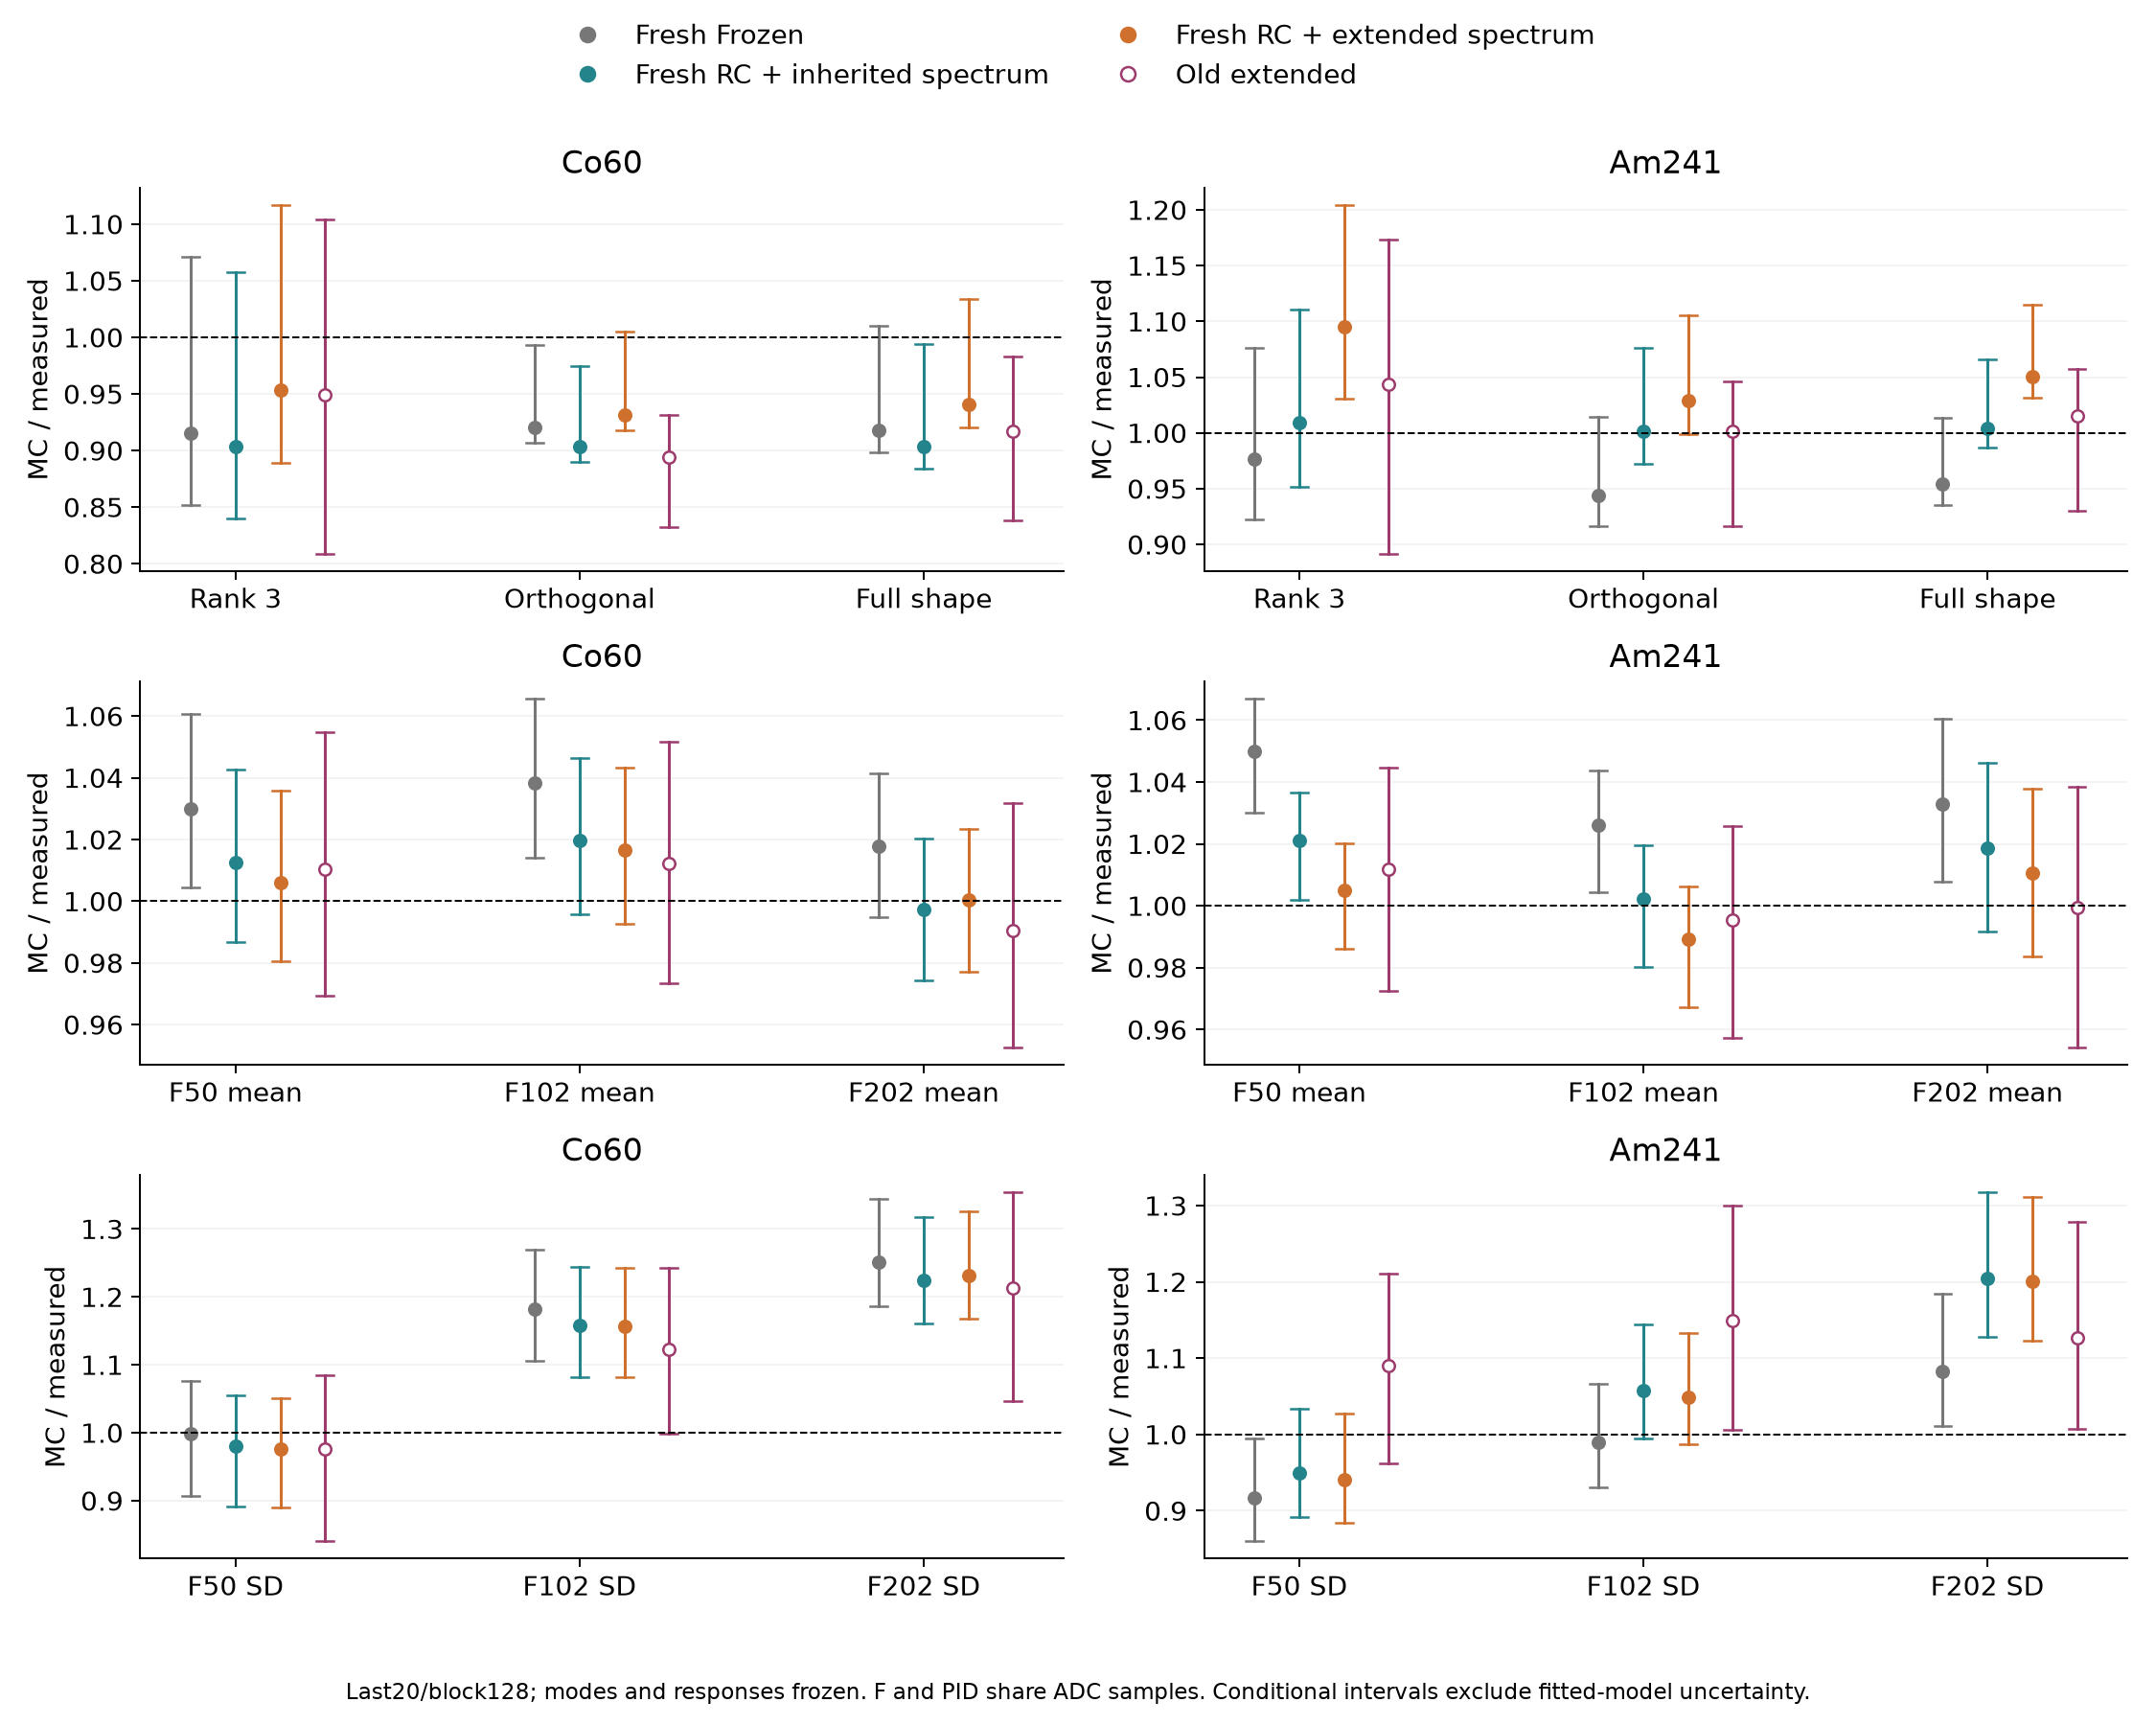

In [7]:
rows=[]
for run in [3,12]:
    r=e['groups'][f'run{run}_last20']['128']['variants']['spectrum_CV_fit']
    for name in ['rank3_variance_ratio','orthogonal_variance_ratio','full_shape_variance_ratio','F50_SD_ratio','F102_SD_ratio','F202_SD_ratio']:
        rows.append([run,name,fmt(r['old_point'][name]),fmt(r['point'][name]),ci(r['CI95'][name])])
display(Markdown(table(['run晚段','指标','旧比','新比','新条件95%区间'],rows)))
display(Image(filename=str(OUT/'figures/independent_modes_and_F.png')))

## 5. 模拟统计与实验区间的贡献

额外保留“仅重采样MC、固定实测点值”和“仅重采样实验、固定MC点值”的条件区间及抽样SD。
二者用于检查目前哪个来源限制精度；由于比值、分位等指标非线性，这些SD不保证平方相加等于联合方差，也不是完整模型误差预算。


In [8]:
rows=[]
for run in [3,12]:
    r=e['groups'][f'run{run}_last20']['128']['variants']['spectrum_CV_fit']
    for name in ['width50_QDC_ratio','width95_negative_mean_time_ratio','width50_PCA_ratio','mean_time_delta_ns','mean_ADC_NRMSE']:
        rows.append([run,name,fmt(r['MC_only_SD'][name],5),fmt(r['data_only_SD'][name],5),ci(r['MC_only_CI95'][name]),ci(r['data_only_CI95'][name])])
display(Markdown(table(['run晚段','指标','仅MC抽样SD','仅实验抽样SD','仅MC条件区间','仅实验条件区间'],rows)))

|run晚段|指标|仅MC抽样SD|仅实验抽样SD|仅MC条件区间|仅实验条件区间|
|---|---|---|---|---|---|
|3|width50_QDC_ratio|0.03004|0.06060|[0.999, 1.114]|[0.874, 1.105]|
|3|width95_negative_mean_time_ratio|0.01909|0.04778|[0.969, 1.041]|[0.912, 1.099]|
|3|width50_PCA_ratio|0.02878|0.06224|[0.897, 1.012]|[0.849, 1.078]|
|3|mean_time_delta_ns|0.32344|0.69007|[0.134, 1.349]|[-0.568, 2.176]|
|3|mean_ADC_NRMSE|0.00034|0.00063|[0.029, 0.031]|[0.029, 0.031]|
|12|width50_QDC_ratio|0.03516|0.05667|[0.944, 1.081]|[0.907, 1.147]|
|12|width95_negative_mean_time_ratio|0.02766|0.04651|[0.925, 1.039]|[0.938, 1.114]|
|12|width50_PCA_ratio|0.03651|0.05227|[0.935, 1.069]|[0.938, 1.155]|
|12|mean_time_delta_ns|0.98437|2.47396|[-1.162, 2.712]|[-4.092, 5.408]|
|12|mean_ADC_NRMSE|0.00089|0.00182|[0.015, 0.018]|[0.014, 0.021]|

## 6. 抽回旧母事件规模的预设诊断

仅检查last20/块128。从新模拟全部原母事件ID中、不放回地随机抽取旧规模（Co8,000、Am24,000），再取其中原已入选的事件，重复512次。
每次继续使用固定原Q、权重、响应折分和实测点值；目标单元缺失则该次不可估计，不补抽事件。至少128次有效才报告范围。
这项检查同时包含有限样本分位估计的偏移和抽样起伏，不能只把旧/新宽度比之差理解为物理噪声强度变化。
这些抽样共享同一批新模拟，不是512批独立输运。95%范围是固定新池和固定实测下的描述范围；旧点在其中的经验位置不是校准后的p值，也不证明差异只有有限统计一个原因。


run 3 抽样母事件数 8000 入选数2.5/50/97.5%分位 [245.0, 273.0, 303.0]
run 12 抽样母事件数 24000 入选数2.5/50/97.5%分位 [163.0, 185.0, 210.22499999999997]


|run晚段|指标|旧点|新合并点|旧规模描述95%范围|有效次数|旧点经验位置|
|---|---|---|---|---|---|---|
|3|width50_QDC_ratio|1.060|1.066|[0.889, 1.195]|512|0.625|
|3|width95_negative_mean_time_ratio|1.004|1.006|[0.845, 1.025]|512|0.934|
|3|width50_PCA_ratio|1.037|0.951|[0.805, 1.103]|512|0.883|
|12|width50_QDC_ratio|1.160|1.014|[0.848, 1.177]|512|0.959|
|12|width95_negative_mean_time_ratio|0.872|0.980|[0.818, 1.060]|512|0.168|
|12|width50_PCA_ratio|1.148|1.005|[0.824, 1.165]|512|0.961|

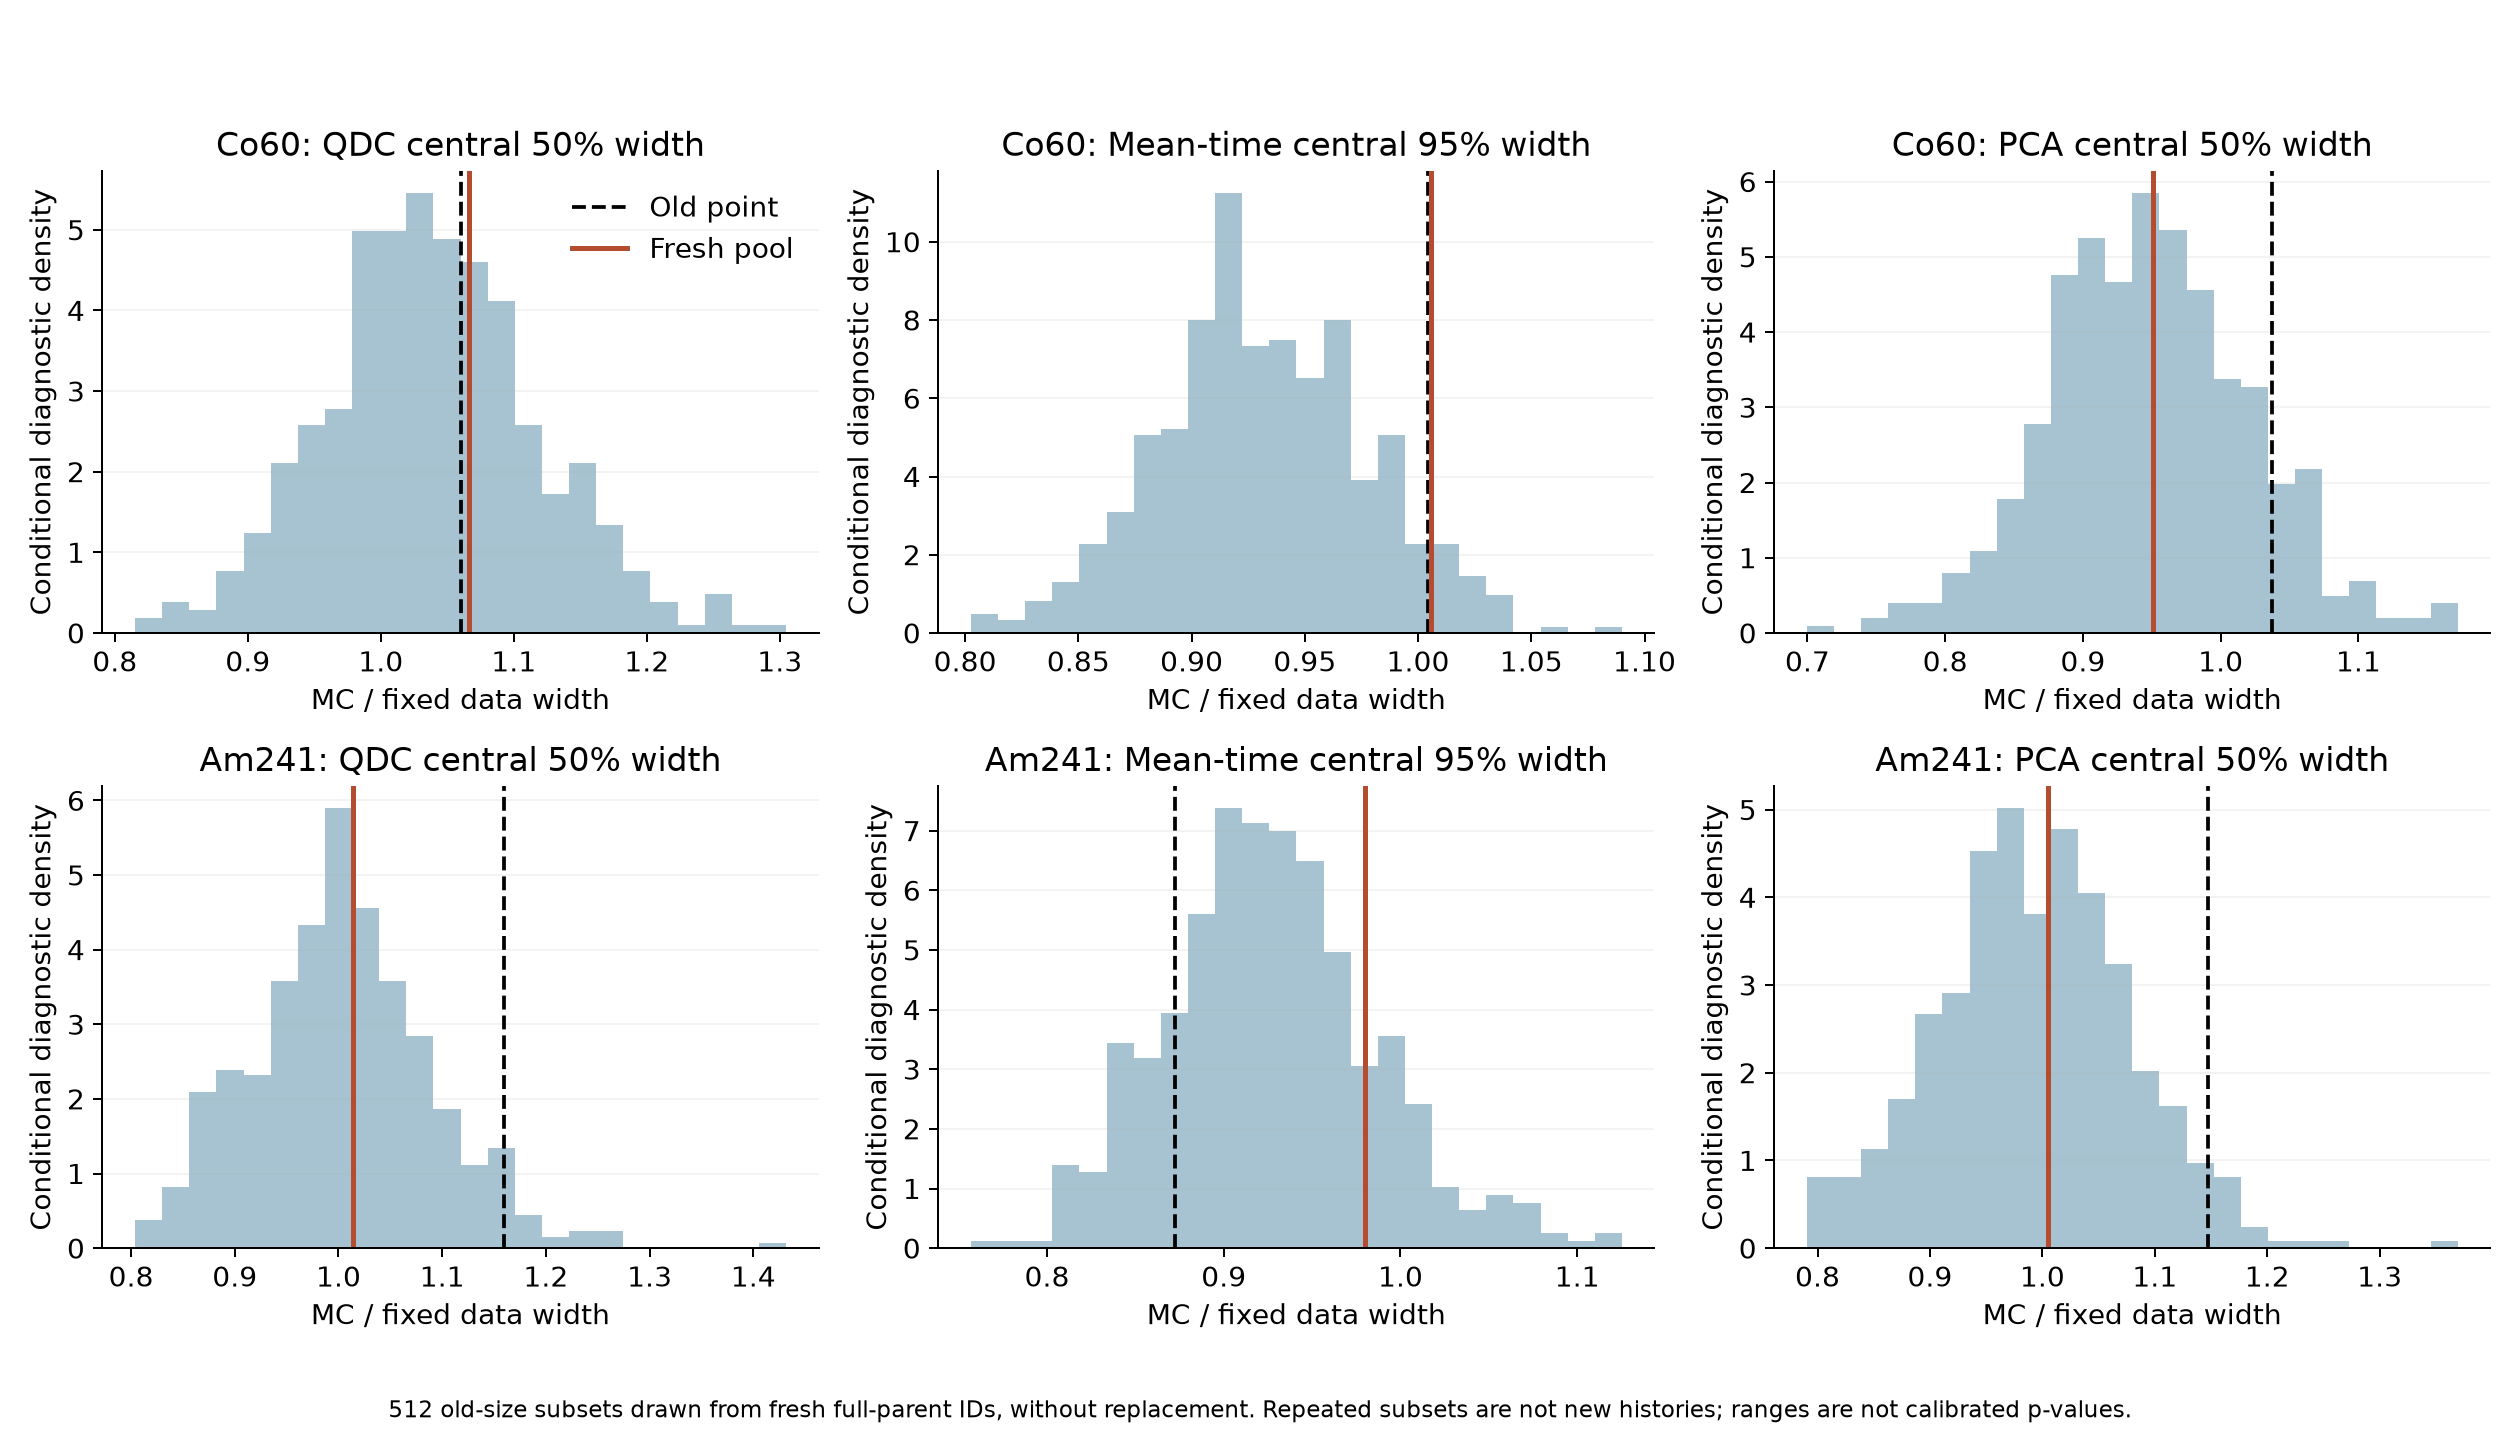

In [9]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128'];r=g['old_size_diagnostic'];a=g['variants']['spectrum_CV_fit']
    print('run',run,'抽样母事件数',r['sampled_full_parent_count'],'入选数2.5/50/97.5%分位',r['selected_count_quantiles'])
    for name in ['width50_QDC_ratio','width95_negative_mean_time_ratio','width50_PCA_ratio']:
        x=r['variants']['spectrum_CV_fit'][name]
        rows.append([run,name,fmt(a['old_point'][name]),fmt(a['point'][name]),ci(x['conditional_range95']),x['conditional_range95']['valid_draws'],fmt(x['old_point_empirical_rank'])])
display(Markdown(table(['run晚段','指标','旧点','新合并点','旧规模描述95%范围','有效次数','旧点经验位置'],rows)))
display(Image(filename=str(OUT/'figures/old_size_MC_subsamples.png')))

## 7. 判断、局限与复现


In [10]:
display(Markdown(decision['conclusion_zh']))
for finding in decision['findings_zh']:display(Markdown(finding))
display(Markdown(decision['next_work_zh']))
for limit in decision['limitations_zh']:display(Markdown('边界：'+limit))
print('默认配置 / 正式PID已改变:',decision['default_changed'],decision['official_PID_changed'])
print('计算: prepare_mc_statistics.py → run_mc_statistics.py transport → run_mc_statistics.py replay → analyze_mc_statistics.py')
print('图/表: plot_mc_statistics.py → summarize_mc_statistics.py')
print('笔记: jupyter/codex_0001_build_mc_statistics_notebook.py；核验/封存: verify_mc_statistics.py [--archive]')
print('结果目录:',OUT)

默认配置 / 正式PID已改变: False False
计算: prepare_mc_statistics.py → run_mc_statistics.py transport → run_mc_statistics.py replay → analyze_mc_statistics.py
图/表: plot_mc_statistics.py → summarize_mc_statistics.py
笔记: jupyter/codex_0001_build_mc_statistics_notebook.py；核验/封存: verify_mc_statistics.py [--archive]
结果目录: /media/sf_works/SiPM/simulation/results/mc_statistics_20261030


完成256000个独立Geant4母衰变，固定Q支持内获得Co 2175、Am 1406个新母事件。冻结扩展谱在Am晚段（块128）的平均时间95%宽度比，从旧样本0.872变为新合并样本0.980，条件95%区间[0.914,1.120]；新减旧的配对区间为[-0.065,0.265]。两源核心及95%宽度的12项检查中，2项条件区间不含1。这些区间未包含拟合和模型不确定性，也未作多重比较校正或等效性检验；本轮不宣称全面一致，默认配置和正式PID保持原样。

Co60晚段扩展谱：新QDC/平均时间/PCA核心宽度比为1.066/0.957/0.951，95%宽度比为1.072/1.006/1.038；均ADC相对L2误差从2.96%变为3.00%，时间中心MC−实测从1.41变为0.77 ns。所有固定模型、四批结果和两种块长均保留。

Am241晚段扩展谱：新QDC/平均时间/PCA核心宽度比为1.014/0.941/1.005，95%宽度比为1.090/0.980/1.034；均ADC相对L2误差从1.40%变为1.60%，时间中心MC−实测从0.68变为0.67 ns。所有固定模型、四批结果和两种块长均保留。

将新Am完整母事件池抽回24000个母事件时，平均时间95%宽度比的512次条件描述范围为[0.818,1.060]，旧点的经验位置为0.168。抽样共享同一新池且固定实测，不是512次独立输运，也不是校准后的p值或单一因果证明。

Am晚段同一指标的仅MC抽样SD为0.0277，仅实验块抽样SD为0.0465。两项用于判断有限统计来源；比值指标非线性，不能把两项方差机械相加当完整误差预算。

... (4 outputs left out)

边界：51项指标、多个段/块长/候选并列，无多重比较校正或预设等效性检验；区间包含1不证明等效，不包含1也不能单独识别噪声原因。

边界：本轮固定基准ADC的选择及Q，评价候选不重新筛选；结论限于既定支持区，不是硬件触发效率、全谱性能或实验粒子鉴别效率。

边界：Am源含α/γ/电子，实验主带没有逐事件真值；仿真祖先标签只用于仿真描述，不能转为实验纯度。

边界：小样本诊断重复使用新模拟池，不能计成新增母事件或独立验证批；四批固定规模的条件bootstrap不代表全部模型不确定性。

`protocol.json`在新输运前冻结种子、配置哈希、二进制哈希、筛选和评价规则。
`native/`保存新完整输运及物理检查，`replay/`保存原生下游响应，`transport/`及`arrays/`保存固定选择和特征，`logs/`记录实际命令、完成状态和文件哈希。
`evaluation/`保存各条件点值和全部配对抽样，`analysis.json`汇总51项指标及四批结果；`comparison_table.csv`和`batch_table.csv`分别含36行旧/新对照和144行逐批点值，`definition_check.json`核查36组旧点值复现。
核验、执行笔记和图像核对后，以`verification.json`、`record.json`及源码快照封存。完整复跑需新结果目录，不能覆盖已封存记录。共享文献库未修改，本轮没有联网调参或补充实验。
